# **1. Introduction**

## **Breast Cancer Prediction Using Decision Tree**

### Machine Learning Decision Tree Classification Project

This project uses a Decision Tree Classifier to predict whether a breast tumour sample is malignant or benign using the Breast Cancer Wisconsin dataset available in Scikit-learn.

### Project Objectives
- Understand Decision Tree Classification.
- Train and evaluate a machine learning model.
- Analyze model performance using classification metrics.
- Visualize the Decision Tree and feature importance.


## **2. Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


## **3. Dataset Loading**

I will use the Breast Cancer Wisconsin dataset provided by Scikit-learn.

The dataset contains measurements of breast tumour characteristics. The target variable has two classes:
- **Malignant** (0): cancerous.
- **Benign** (1): non-cancerous.

The dataset contains 569 samples and 30 numerical input features.

In [2]:
# Load the Breast Cancer dataset

data = load_breast_cancer()

# Separate features and target
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset loaded successfully.")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully.
Features shape: (569, 30)
Target shape: (569,)


## **4. Exploratory Data Analysis (EDA)**

Exploratory Data Analysis involves examining a dataset to understand its structure, features, distributions, and target classes before training a machine learning model.

In [3]:
# Display the first five rows
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
# Display dataset information

print("Number of rows:", X.shape[0])
print("Number of columns:", X.shape[1])

print("\nDataset information:")
X.info()

Number of rows: 569
Number of columns: 30

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error      

In [5]:
# Check missing values in each feature

missing_values = X.isnull().sum()

print("Total missing values:", missing_values.sum())

Total missing values: 0


## **Analyze Target Class Distribution**

Before training the model, lets examine how many samples belong to each target class.

This helps understand whether the dataset contains a similar number of samples from both classes or whether one class is more common.

In [6]:
# Count the samples in each class

class_counts = pd.Series(y).map(
    {0: "Malignant", 1: "Benign"}
).value_counts()

print(class_counts)

Benign       357
Malignant    212
Name: count, dtype: int64


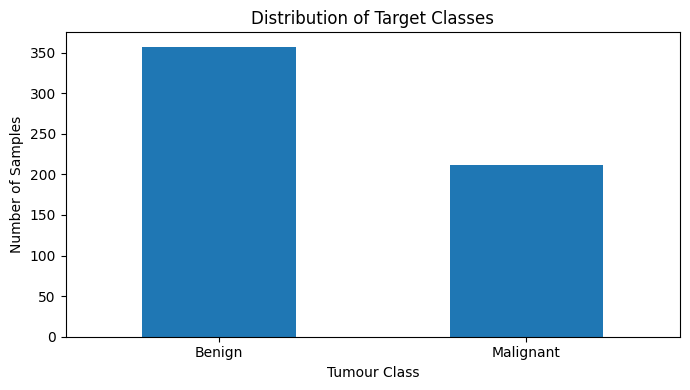

In [7]:
# Visualize class distribution
class_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Distribution of Target Classes")
plt.xlabel("Tumour Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## **5. Train-Test Split**

Lets divide the dataset into training and testing sets.

- Training set: 80% of the data, used to train the model.
- Testing set: 20% of the data, used to evaluate its performance on unseen samples.

I use `stratify=y` to preserve approximately the same class proportions in both sets.

In [8]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training features: (455, 30)
Testing features: (114, 30)
Training samples: 455
Testing samples: 114


## **6. Model Building**

Decision Tree is a supervised machine learning algorithm that makes predictions by repeatedly splitting data based on feature values.

I will use entropy as the splitting criterion. Entropy measures the impurity of a group, while Information Gain measures how much a split reduces that impurity.

I will also set `max_depth=4` to limit the tree's depth and help control overfitting.

In [9]:
# Create the Decision Tree Classifier

classifier = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=42
)

print("Decision Tree model created successfully.")

Decision Tree model created successfully.


In [10]:
# Train the model

classifier.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


### **Model Predictions**

After training, I will use the model to predict the target classes of the testing samples.

These predictions will be compared with the actual target labels to evaluate model performance.

In [11]:
# Predict the target classes for test data

y_pred = classifier.predict(X_test)

print("Predictions generated successfully.")
print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test[:10])

Predictions generated successfully.
First 10 predictions: [0 1 0 1 0 1 1 0 0 0]
First 10 actual values: [0 1 0 1 0 1 1 0 0 0]


## **7. Model Evaluation**

I will evaluate the model using accuracy, precision, recall, and F1-score.

Accuracy measures the proportion of correct predictions. Precision, recall, and F1-score provide additional information about how well the model identifies each class.

In [12]:
# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy)
print("Decision Tree Accuracy (%):", accuracy * 100,"%")

Decision Tree Accuracy: 0.9385964912280702
Decision Tree Accuracy (%): 93.85964912280701 %


In [13]:
# Display the classification report

print(
    classification_report(y_test,y_pred,
        target_names=data.target_names
    )
)

              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



## **8. Confusion Matrix**

A confusion matrix compares actual classes with predicted classes.

It helps to identify correct predictions and classification errors for both malignant and benign samples.

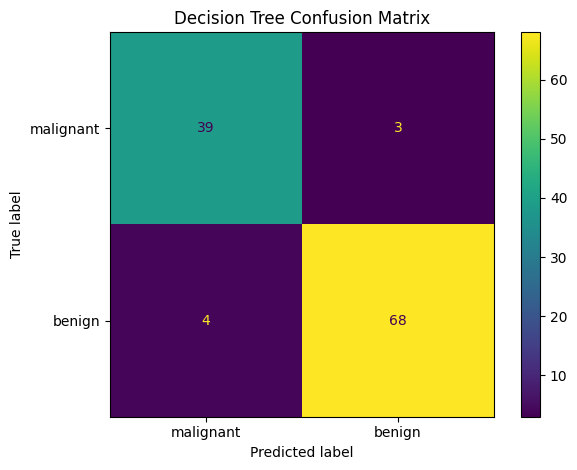

In [14]:
# Generate the confusion matrix

cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

display.plot()

plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

## **9. Decision Tree Visualization**

I will visualize the trained Decision Tree to understand how it makes predictions.

Each internal node represents a decision based on a feature, each branch represents an outcome of that decision, and each leaf node represents the final predicted class.

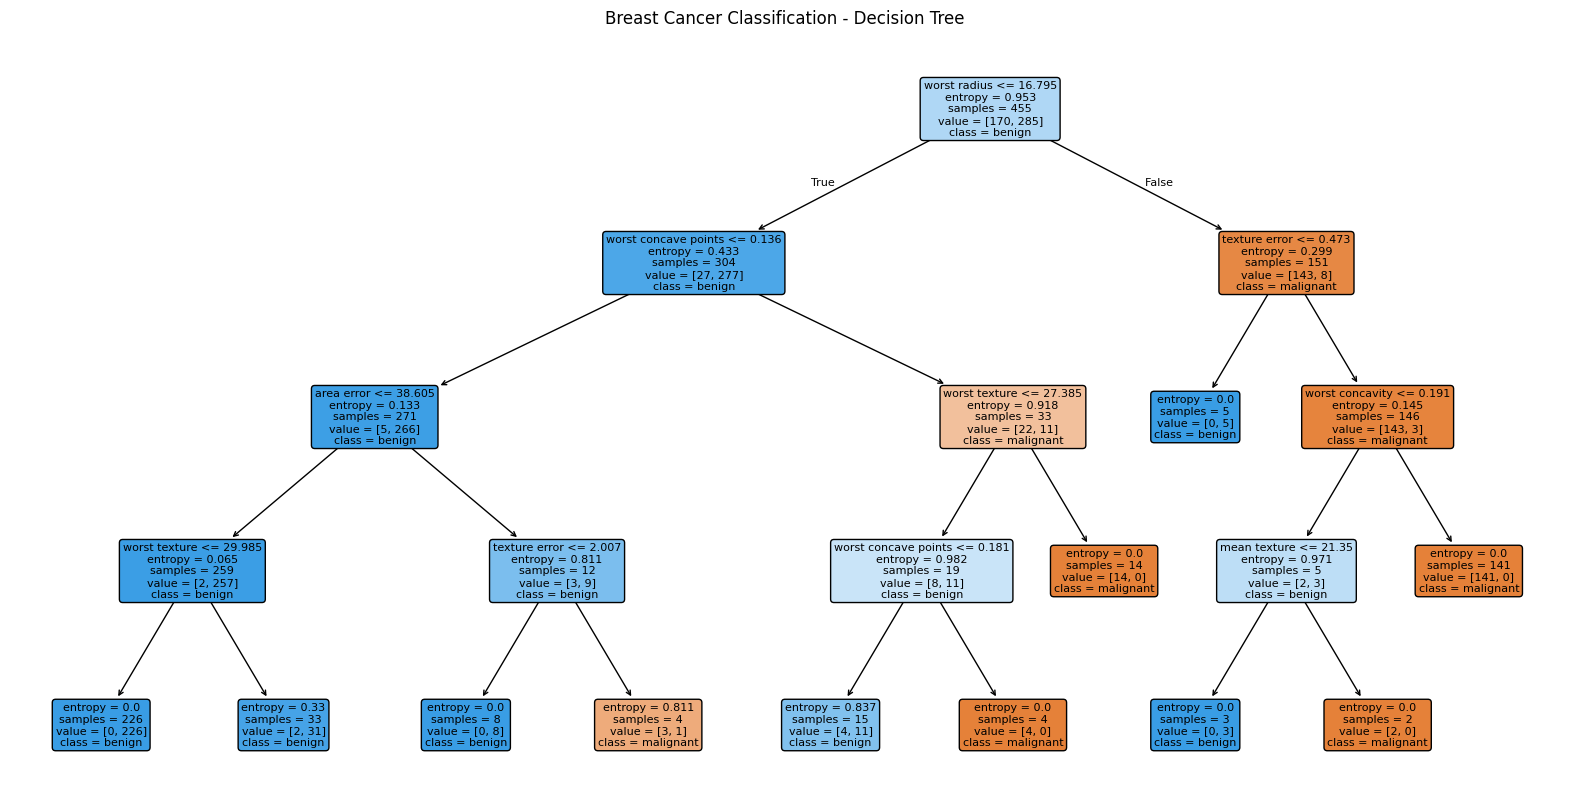

In [15]:
# Visualize the trained Decision Tree

plt.figure(figsize=(20, 10))

plot_tree(
    classifier,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Breast Cancer Classification - Decision Tree")
plt.show()

## **10. Feature Importance**

Feature importance shows how much each feature contributes to the Decision Tree's splitting decisions.

I will rank the features by their importance scores and visualize the top 10.

These scores describe the model's behavior and should not be interpreted as proof of medical significance or causation.

In [16]:
# Calculate feature importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": classifier.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
20,worst radius,0.631712
27,worst concave points,0.175222
11,texture error,0.074989
21,worst texture,0.043401
26,worst concavity,0.039897
13,area error,0.022854
1,mean texture,0.011924
4,mean smoothness,0.000000
6,mean concavity,0.000000
7,mean concave points,0.000000


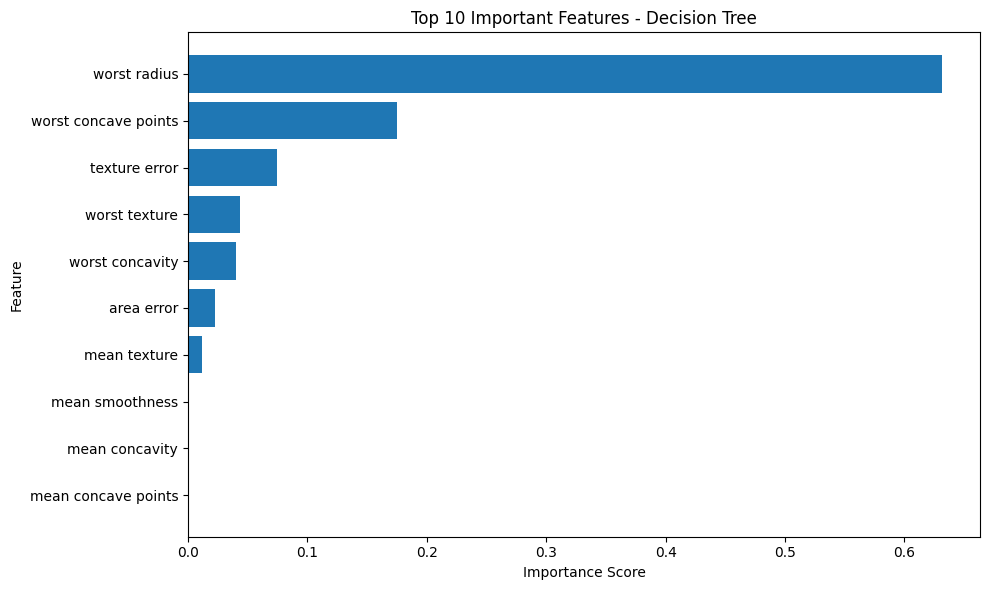

In [17]:
# Plot the top 10 important features

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Important Features - Decision Tree")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## **11. Predicting a Single Sample**

Finally, I will select one sample from the test dataset and display the model's prediction alongside its actual class.

This demonstrates how the trained model can predict the class of an individual sample.

In [18]:
# Select one sample from the test dataset

sample = X_test.iloc[[0]]

# Predict the class
prediction = classifier.predict(sample)

# Display predicted and actual classes
print("Predicted Class:", data.target_names[prediction[0]])
print("Actual Class:", data.target_names[y_test[0]])

Predicted Class: malignant
Actual Class: malignant


## 12. Conclusion

In this project, I developed a Decision Tree Classification model using the Breast Cancer Wisconsin dataset.

I explored the dataset, split it into training and testing sets, trained the model using entropy, and evaluated its performance using accuracy, precision, recall, F1-score, and a confusion matrix.

I also visualized the trained Decision Tree and examined feature importance to understand the model's splitting decisions.

This project demonstrates the basic workflow of a supervised machine learning classification problem.

### Future Improvements
- Compare entropy and Gini impurity.
- Tune hyperparameters using cross-validation.
- Compare Decision Tree performance with Random Forest.
- Evaluate the model's ability to identify malignant samples carefully.
